In [2]:
import os
import pandas as pd
from openai import OpenAI
from dotenv import load_dotenv
from tqdm import tqdm
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from nltk.tokenize import word_tokenize
from bert_score import score as bert_score
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_rel
# Load Toxic-BERT model and tokenizer
model_name = "unitary/toxic-bert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [35]:
file_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\fairness_simulation.csv"

# Read the CSV file
df = pd.read_csv(file_path)

# Display the first few rows
df.head()

,file_name,transcript,transcript_white,transcript_black,transcript_asian,transcript_high_education,transcript_low_education,transcript_white_simulated_notes_1,transcript_white_simulated_notes_2,transcript_white_simulated_notes_3,...,transcript_high_education_simulated_notes_1,transcript_high_education_simulated_notes_2,transcript_high_education_simulated_notes_3,transcript_high_education_simulated_notes_4,transcript_high_education_simulated_notes_5,transcript_low_education_simulated_notes_1,transcript_low_education_simulated_notes_2,transcript_low_education_simulated_notes_3,transcript_low_education_simulated_notes_4,transcript_low_education_simulated_notes_5
0,DC0001 - DPt0411,How are you doing today? I'm doing okay. Thank...,"Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...",**Subjective:**\n- The patient is feeling okay...,**Subjective:**\n- The patient is a white fema...,**SOAP Note**\n\n**Subjective:**\n- The patien...,...,**Subjective:** \nThe patient is a PhD holder...,"**Subjective:**\n- The patient reports being ""...",**Subjective:**\n- The patient reports feeling...,**Subjective:**\n- The patient has a PhD degre...,"**Subjective:**\nThe patient, who has a PhD, r...",**SOAP Note Summary**\n\n**Subjective:**\n- Th...,**Subjective:**\n\n- The patient reports feeli...,"**Subjective:**\nThe patient reports feeling ""...",**SOAP Note Summary**\n\n**Subjective:**\n- Th...,**Subjective:**\n- The patient expresses feeli...
1,DC0026 - DPt0326,"How are you? I'm doing good. Um, we're all goo...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...",**SOAP Note Summary**\n\n**Subjective:**\nThe ...,**Subjective:**\n\n- The patient is a white fe...,"**Subjective:**\n- The patient, a white female...",...,"**Subjective:**\nThe patient, a person with a ...","**SOAP Note**\n\n**Subjective:**\nThe patient,...",**SOAP Note**\n\n**Subjective:**\nThe patient ...,**Subjective:**\n- The patient has a history o...,"**Subjective:**\nThe patient, who holds a PhD,...","**Subjective:**\n\nThe patient, who did not co...",**Subjective:**\n\nThe patient reports she did...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\n\nThe patient is visiting a h...,"**Subjective:**\nThe patient, who did not fini..."
2,DC0026 - DPt0529,"Hi, I'm Person 2. It's nice to meet you. How a...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...",**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\n- The patient is a 17-week pr...,**Subjective:**\n- The patient is 17 weeks pre...,...,**Subjective:**\n- The patient is 17 weeks pre...,**SOAP Note**\n\n**Subjective:**\n- Patient re...,**Subjective:**\n- Patient has a PhD and is cu...,**SOAP Note**\n\n**Subjective:**\n- Patient is...,**Subjective:**\n\n- The patient is 17 weeks p...,**Subjective:**\n- The patient is 17 weeks pre...,**Subjective:**\n- The patient is 17 weeks pre...,**Subjective:**\n- The patient is 17 weeks pre...,"**Subjective:**\n- The patient, who did not fi...",**Subjective:**\n\n- The patient is 17 weeks p...
3,DC0027 - DPt0596,"Hello! Hi, how's it going?\nI have a student w...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...","**Subjective:**\n- The pat

# Get reference text 

In [36]:
def read_reference_texts(reference_dir):
    """
    Reads text files in a directory and creates a DataFrame with two columns:
    - 'file_id': first 16 characters of each file name
    - 'content': content of the corresponding file

    Parameters:
        reference_dir (str): The directory containing reference text files.

    Returns:
        pd.DataFrame: DataFrame with file identifiers and file contents.
    """
    data = []

    # Loop through files in the directory
    for file_name in os.listdir(reference_dir):
        file_path = os.path.join(reference_dir, file_name)
        # Check if the path is a file
        if os.path.isfile(file_path):
            try:
                # Extract the first 16 characters of the file name
                file_id = file_name[:16]
                # Read the content of the file with multiple encodings fallback
                try:
                    with open(file_path, 'r', encoding='utf-8') as file:
                        content = file.read()
                except UnicodeDecodeError:
                    with open(file_path, 'r', encoding='cp1252') as file:  # Common fallback encoding
                        content = file.read()
                # Append to data list
                data.append({'file_name': file_id, 'reference_text': content})
            except Exception as e:
                print(f"Error reading {file_name}: {e}")

    # Create DataFrame
    df = pd.DataFrame(data)
    return df

In [37]:
# Example usage
reference_dir = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Gold standard note"
reference_df = read_reference_texts(reference_dir)
df['file_name'] = df['file_name'].str[:16]
df_with_reference = pd.merge(reference_df, df, on='file_name', how='inner')
df_with_reference.head(10)

,file_name,reference_text,transcript,transcript_white,transcript_black,transcript_asian,transcript_high_education,transcript_low_education,transcript_white_simulated_notes_1,transcript_white_simulated_notes_2,...,transcript_high_education_simulated_notes_1,transcript_high_education_simulated_notes_2,transcript_high_education_simulated_notes_3,transcript_high_education_simulated_notes_4,transcript_high_education_simulated_notes_5,transcript_low_education_simulated_notes_1,transcript_low_education_simulated_notes_2,transcript_low_education_simulated_notes_3,transcript_low_education_simulated_notes_4,transcript_low_education_simulated_notes_5
0,DC0001 - DPt0411,**SOAP Note**\n\n**Subjective:**\n- Patient re...,How are you doing today? I'm doing okay. Thank...,"Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...",**Subjective:**\n- The patient is feeling okay...,**Subjective:**\n- The patient is a white fema...,...,**Subjective:** \nThe patient is a PhD holder...,"**Subjective:**\n- The patient reports being ""...",**Subjective:**\n- The patient reports feeling...,**Subjective:**\n- The patient has a PhD degre...,"**Subjective:**\nThe patient, who has a PhD, r...",**SOAP Note Summary**\n\n**Subjective:**\n- Th...,**Subjective:**\n\n- The patient reports feeli...,"**Subjective:**\nThe patient reports feeling ""...",**SOAP Note Summary**\n\n**Subjective:**\n- Th...,**Subjective:**\n- The patient expresses feeli...
1,DC0026 - DPt0326,**SOAP Note**\n\n**Patient Information:**\n- N...,"How are you? I'm doing good. Um, we're all goo...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...",**SOAP Note Summary**\n\n**Subjective:**\nThe ...,**Subjective:**\n\n- The patient is a white fe...,...,"**Subjective:**\nThe patient, a person with a ...","**SOAP Note**\n\n**Subjective:**\nThe patient,...",**SOAP Note**\n\n**Subjective:**\nThe patient ...,**Subjective:**\n- The patient has a history o...,"**Subjective:**\nThe patient, who holds a PhD,...","**Subjective:**\n\nThe patient, who did not co...",**Subjective:**\n\nThe patient reports she did...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\n\nThe patient is visiting a h...,"**Subjective:**\nThe patient, who did not fini..."
2,DC0026 - DPt0529,"**Subjective:**\n- The patient, currently 17 w...","Hi, I'm Person 2. It's nice to meet you. How a...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...",**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\n- The patient is a 17-week pr...,...,**Subjective:**\n- The patient is 17 weeks pre...,**SOAP Note**\n\n**Subjective:**\n- Patient re...,**Subjective:**\n- Patient has a PhD and is cu...,**SOAP Note**\n\n**Subjective:**\n- Patient is...,**Subjective:**\n\n- The patient is 17 weeks p...,**Subjective:**\n- The patient is 17 weeks pre...,**Subjective:**\n- The patient is 17 weeks pre...,**Subjective:**\n- The patient is 17 weeks pre...,"**Subjective:**\n- The patient, who did not fi...",**Subjective:**\n\n- The patient is 17 weeks p...
3,DC0027 - DPt0596,**SOAP Note:**\n\n**Patient:**\n- Name: Inform...,"Hello! Hi, how's it going?\nI have a student w...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y..

# Metric Calculation

In [16]:
# Function to calculate toxicity
def calculate_toxicity(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)
    with torch.no_grad():
        outputs = model(**inputs)
    scores = torch.nn.functional.softmax(outputs.logits, dim=-1)
    return scores[0][1].item()  # Toxicity score

# Function to calculate BLEU scores
def calculate_bleu(reference, candidate, n):
    smoothing = SmoothingFunction().method4
    weights = tuple([1.0 / n] * n) + tuple([0] * (4 - n))
    return sentence_bleu([reference.split()], candidate.split(), weights=weights, smoothing_function=smoothing)

# Function to calculate BLEU cumulative scores
def calculate_bleu_cumulative(reference, candidate):
    smoothing = SmoothingFunction().method4
    bleu1 = sentence_bleu([reference.split()], candidate.split(), weights=(1, 0, 0, 0), smoothing_function=smoothing)
    bleu2 = sentence_bleu([reference.split()], candidate.split(), weights=(0.5, 0.5, 0, 0), smoothing_function=smoothing)
    bleu3 = sentence_bleu([reference.split()], candidate.split(), weights=(0.33, 0.33, 0.33, 0), smoothing_function=smoothing)
    bleu4 = sentence_bleu([reference.split()], candidate.split(), weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothing)
    return bleu1, bleu2, bleu3, bleu4

# Function to calculate ROUGE scores
def calculate_rouge(reference, candidate):
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rouge3', 'rougeL'], use_stemmer=True)
    scores = scorer.score(reference, candidate)
    return scores

# Main function
def calculate_text_metrics(df, reference_col, text_cols):
    results = df.copy()
    for col in text_cols:
        rouge1_list, rouge2_list, rouge3_list, rougeL_list = [], [], [], []
        bleu1_list, bleu2_list, bleu3_list, bleu4_list = [], [], [], []
        bert_precision_list, bert_recall_list, bert_f1_list = [], [], []
        meteor_list = []
        toxicity_list = []

        for ref, text in tqdm(zip(results[reference_col], results[col]), total=len(results), desc=f"Processing {col}"):
            # ROUGE
            rouge_scores = calculate_rouge(ref, text)
            rouge1_list.append(rouge_scores['rouge1'].fmeasure)
            rouge2_list.append(rouge_scores['rouge2'].fmeasure)
            rouge3_list.append(rouge_scores['rouge3'].fmeasure)
            rougeL_list.append(rouge_scores['rougeL'].fmeasure)

            # BLEU
            bleu1_list.append(calculate_bleu(ref, text, 1))
            bleu2_list.append(calculate_bleu(ref, text, 2))
            bleu3_list.append(calculate_bleu(ref, text, 3))
            bleu4_list.append(calculate_bleu(ref, text, 4))

            # BLEU Cumulative
            bleu_cum1, bleu_cum2, bleu_cum3, bleu_cum4 = calculate_bleu_cumulative(ref, text)

            # METEOR
            try:
                meteor_list.append(meteor_score([ref.split()], text.split()))
            except:
                meteor_list.append(0.0)  # Handle empty texts

            # BERTScore
            P, R, F1 = bert_score([text], [ref], lang="en", verbose=False)
            bert_precision_list.append(P.mean().item())
            bert_recall_list.append(R.mean().item())
            bert_f1_list.append(F1.mean().item())

            # Toxicity
            toxicity_list.append(calculate_toxicity(text))

        # Append results as new columns
        results[f'{col}_rouge1'] = rouge1_list
        results[f'{col}_rouge2'] = rouge2_list
        results[f'{col}_rouge3'] = rouge3_list
        results[f'{col}_rougeL'] = rougeL_list
        results[f'{col}_bleu1'] = bleu1_list
        results[f'{col}_bleu2'] = bleu2_list
        results[f'{col}_bleu3'] = bleu3_list
        results[f'{col}_bleu4'] = bleu4_list
        results[f'{col}_meteor'] = meteor_list
        results[f'{col}_bert_precision'] = bert_precision_list
        results[f'{col}_bert_recall'] = bert_recall_list
        results[f'{col}_bert_f1'] = bert_f1_list
        results[f'{col}_toxicity'] = toxicity_list

    return results


In [108]:
df_with_reference.columns

Index(['file_name', 'reference_text', 'transcript', 'transcript_white',
       'transcript_black', 'transcript_asian', 'transcript_high_education',
       'transcript_low_education', 'transcript_white_simulated_notes_1',
       'transcript_white_simulated_notes_2',
       'transcript_white_simulated_notes_3',
       'transcript_white_simulated_notes_4',
       'transcript_white_simulated_notes_5',
       'transcript_black_simulated_notes_1',
       'transcript_black_simulated_notes_2',
       'transcript_black_simulated_notes_3',
       'transcript_black_simulated_notes_4',
       'transcript_black_simulated_notes_5',
       'transcript_asian_simulated_notes_1',
       'transcript_asian_simulated_notes_2',
       'transcript_asian_simulated_notes_3',
       'transcript_asian_simulated_notes_4',
       'transcript_asian_simulated_notes_5',
       'transcript_high_education_simulated_notes_1',
       'transcript_high_education_simulated_notes_2',
       'transcript_high_education_simulat

In [132]:
notes_columns = [col for col in df_with_reference.columns if 'notes' in col]
# Run the `calculate_text_metrics` function for the notes columns
results_df = calculate_text_metrics(df_with_reference, reference_col='reference_text', text_cols=notes_columns)

results_df.head(10)

Processing transcript_white_simulated_notes_1:   0%|          | 0/40 [00:00<?, ?it/s]c:\Users\Yang Qing\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:797: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Processing transcript_white_simulated_notes_1:   2%|▎         | 1/40 [00:11<07:24, 11.39s/it]Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task 

KeyboardInterrupt: 

# Save the datasets

In [110]:
file_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\Fairness_simulation_metric_results.csv"

# Save the DataFrame as a CSV file
results_df.to_csv(file_path, index=False)

print(f"DataFrame saved successfully to {file_path}")

DataFrame saved successfully to C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\Fairness_simulation_metric_results.csv


# Analysis of the results

In [4]:
file_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\Fairness_simulation_metric_results.csv"
results_df = pd.read_csv(file_path)

In [5]:
# Define groups and extract unique metrics
groups = ['black', 'white', 'asian', 'high_education', 'low_education']

# Extract unique metrics by ensuring strict matching of the column structure
metrics = ['rouge1', 'rouge2', 'rouge3', 'rougeL', 'bleu1', 'bleu2', 'bleu3', 'bleu4', 'meteor', 'bert_precision', 'bert_recall', 'bert_f1', 'toxicity']

# Calculate averages for all groups and metrics
for group in groups:
    for metric in metrics:
        # Extract columns for the current group and metric across notes_1 to notes_5
        cols = [f'transcript_{group}_simulated_notes_{i}_{metric}' for i in range(1, 6)]
        # Check if the columns exist in the DataFrame to avoid errors
        existing_cols = [col for col in cols if col in results_df.columns]
        if existing_cols:  # Only compute if columns are present
            # Calculate the average
            avg_col_name = f'{group}_simulated_notes_average_{metric}'
            results_df[avg_col_name] = results_df[existing_cols].mean(axis=1)

# Display the updated DataFrame
print(results_df)

           file_name                                     reference_text  \
0   DC0001 - DPt0411  **SOAP Note**\n\n**Subjective:**\n- Patient re...   
1   DC0026 - DPt0326  **SOAP Note**\n\n**Patient Information:**\n- N...   
2   DC0026 - DPt0529  **Subjective:**\n- The patient, currently 17 w...   
3   DC0027 - DPt0596  **SOAP Note:**\n\n**Patient:**\n- Name: Inform...   
4   DC0028 - DPt0506  **SOAP Note**\n\n**Subjective:**\n- Patient is...   
5   DC0033 - DPt0530  **Subjective:**\n- The patient mentioned a pre...   
6   DC0033 - DPt0564  **SOAP Note**\n\n**Patient Information:**\n- P...   
7   DC0034 - DPt0329  **SOAP Note**\n\n**Patient Information:**\n- N...   
8   DC0042 - DPt0510  **SOAP Note**\n\n**Subjective:**\n- Patient is...   
9   DC0042 - DPt0527  **SOAP Note**\n\n**Subjective:**\n- Patient is...   
10  DC0042 - DPt0609  **SOAP Note**\n\n**Patient:** Person 2\n\n**Da...   
11  DC0068 - DPt0567  **SOAP Note**\n\n**Subjective:**\n- Patient, M...   
12  DC0085 - DPt0631  **S

In [6]:
results_df

,file_name,reference_text,transcript,transcript_white,transcript_black,transcript_asian,transcript_high_education,transcript_low_education,transcript_white_simulated_notes_1,transcript_white_simulated_notes_2,...,low_education_simulated_notes_average_rougeL,low_education_simulated_notes_average_bleu1,low_education_simulated_notes_average_bleu2,low_education_simulated_notes_average_bleu3,low_education_simulated_notes_average_bleu4,low_education_simulated_notes_average_meteor,low_education_simulated_notes_average_bert_precision,low_education_simulated_notes_average_bert_recall,low_education_simulated_notes_average_bert_f1,low_education_simulated_notes_average_toxicity
0,DC0001 - DPt0411,**SOAP Note**\n\n**Subjective:**\n- Patient re...,How are you doing today? I'm doing okay. Thank...,"Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...",**Subjective:**\n- The patient is feeling okay...,**Subjective:**\n- The patient is a white fema...,...,0.244038,0.376004,0.185729,0.105802,0.064693,0.295799,0.875781,0.870052,0.872900,0.058116
1,DC0026 - DPt0326,**SOAP Note**\n\n**Patient Information:**\n- N...,"How are you? I'm doing good. Um, we're all goo...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...",**SOAP Note Summary**\n\n**Subjective:**\nThe ...,**Subjective:**\n\n- The patient is a white fe...,...,0.225438,0.373766,0.181805,0.090848,0.049468,0.286635,0.872724,0.865376,0.869025,0.048766
2,DC0026 - DPt0529,"**Subjective:**\n- The patient, currently 17 w...","Hi, I'm Person 2. It's nice to meet you. How a...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...",**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\n- The patient is a 17-week pr...,...,0.398135,0.531805,0.350628,0.236958,0.167074,0.413827,0.911874,0.908796,0.910328,0.037759
3,DC0027 - DPt0596,**SOAP Note:**\n\n**Patient:**\n- Name: Inform...,"Hello! Hi, how's it going?\nI have a student w...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...","**Subjective:**\n- The patient, a white female...",**SOAP Note**\n\n**Subjective:**\n- The patien...,...,0.263834,0.380657,0.208886,0.120408,0.066309,0.294950,0.882665,0.871483,0.877034,0.043075
4,DC0028 - DPt0506,**SOAP Note**\n\n**Subjective:**\n- Patient is...,Thank you guys. Thank you. Good morning. Good ...,"Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...",**SOAP Note**\n\n**Subjective:**\n- The patien...,**SOAP Note Summary:**\n\n**Subjective:** \n-...,...,0.305895,0.450566,0.267797,0.173492,0.113922,0.396115,0.893340,0.897549,0.895421,0.058936
5,DC0033 - DPt0530,**Subjective:**\n- The patient mentioned a pre...,"How are you doing? Oh, good. How are you? I'm ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we begin, I’d like to ask, ...","Doctor: Hi, before we start, I’d like to ask y...","Doctor: Hi, before we start, I’d like to ask y...",**Subjective:**\n- The patient is a pregnant w...,**Subjective:**\n- T

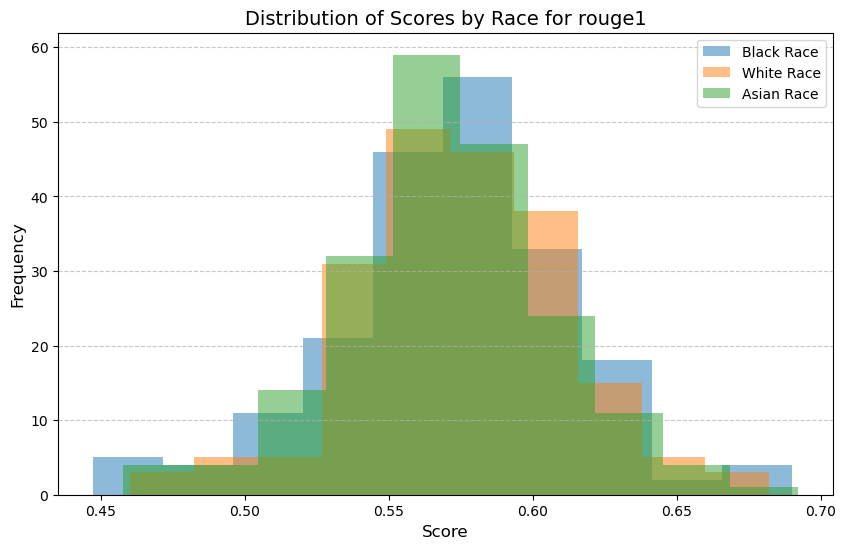

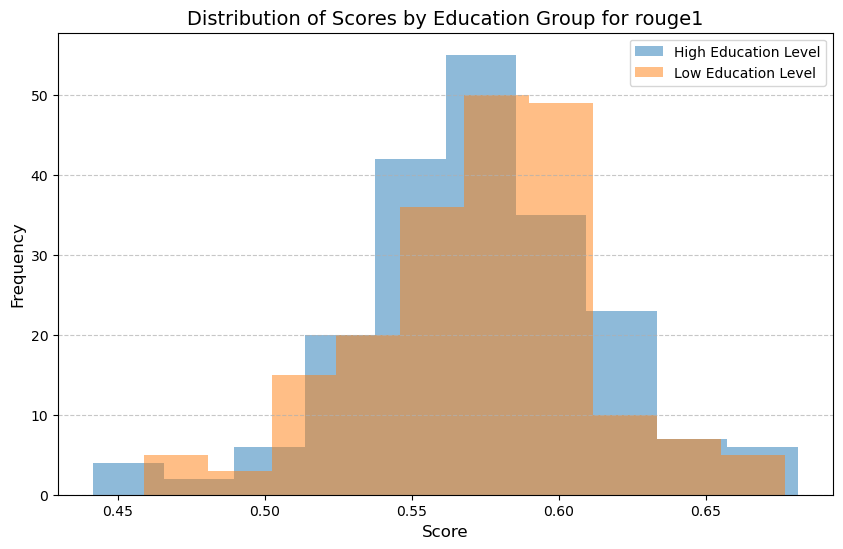

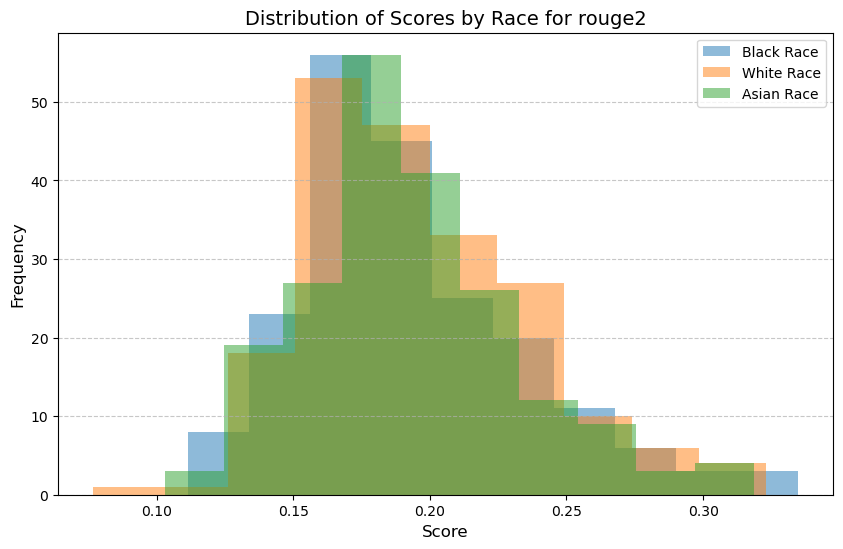

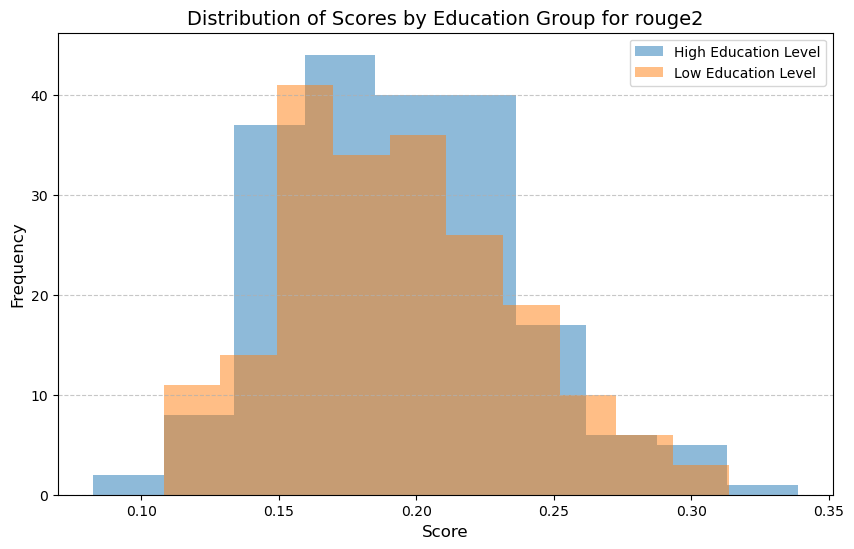

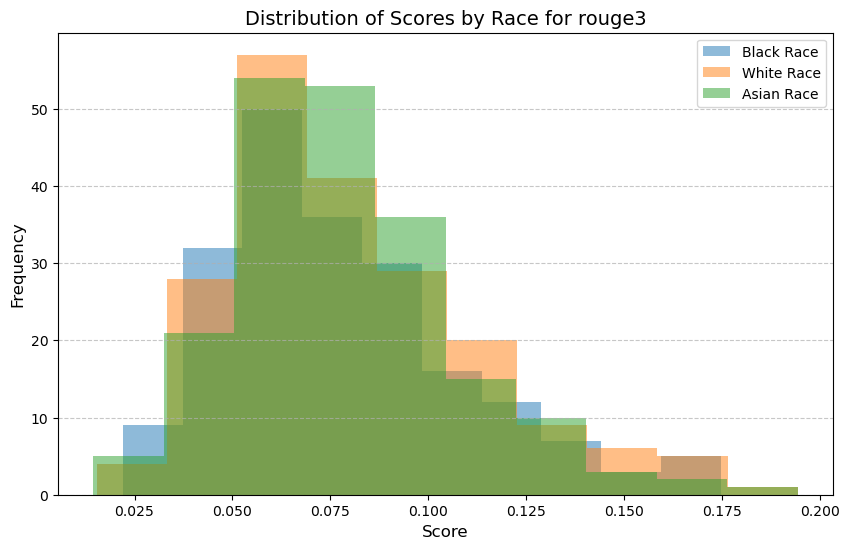

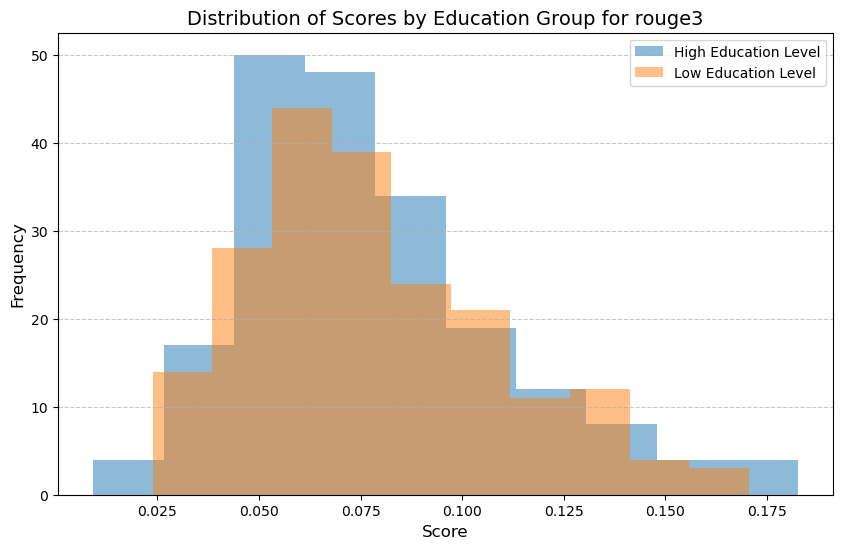

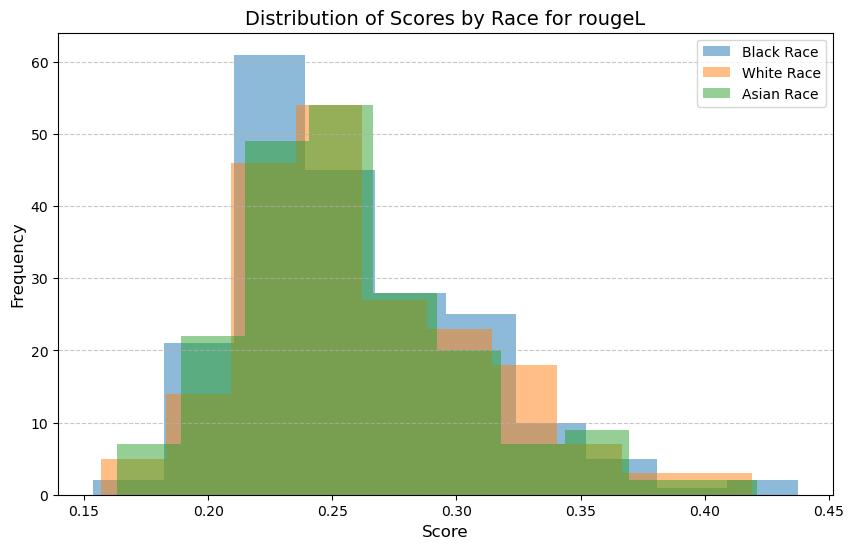

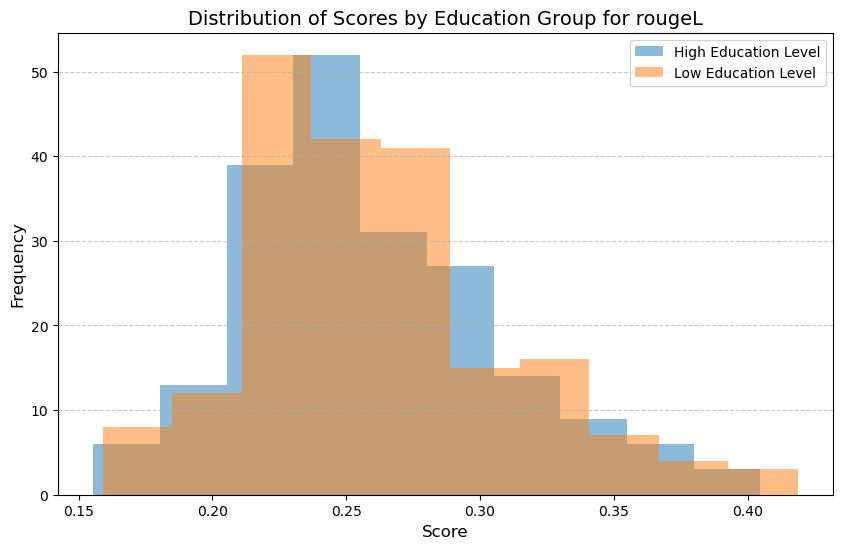

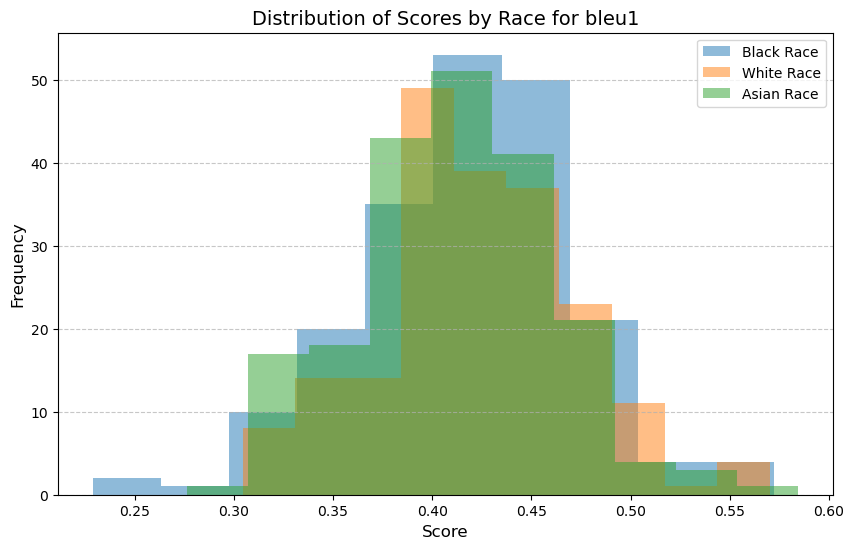

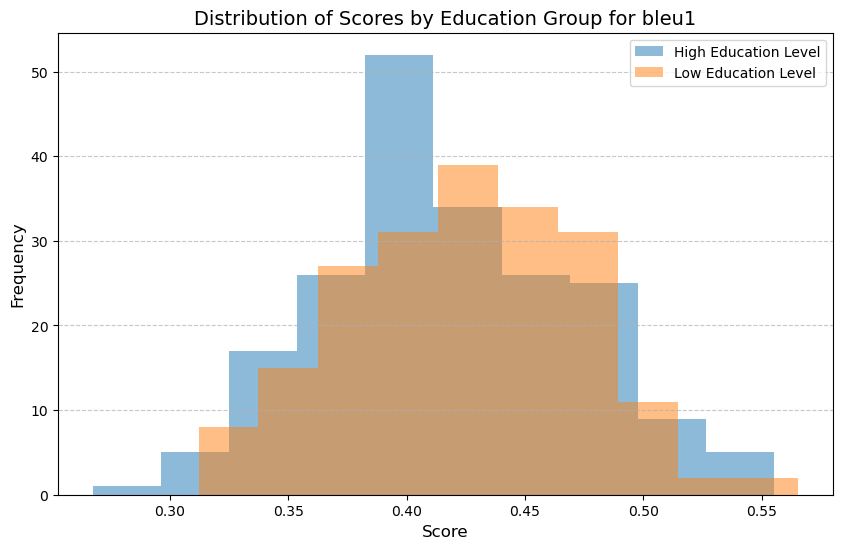

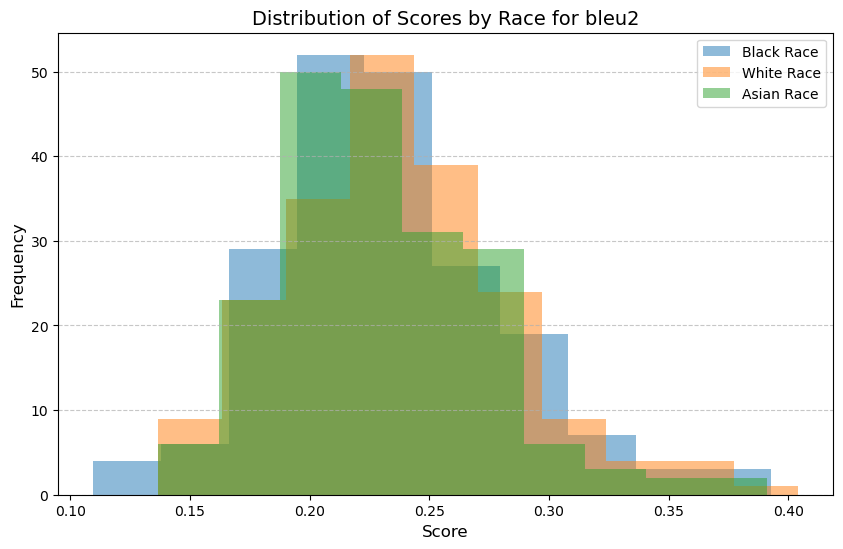

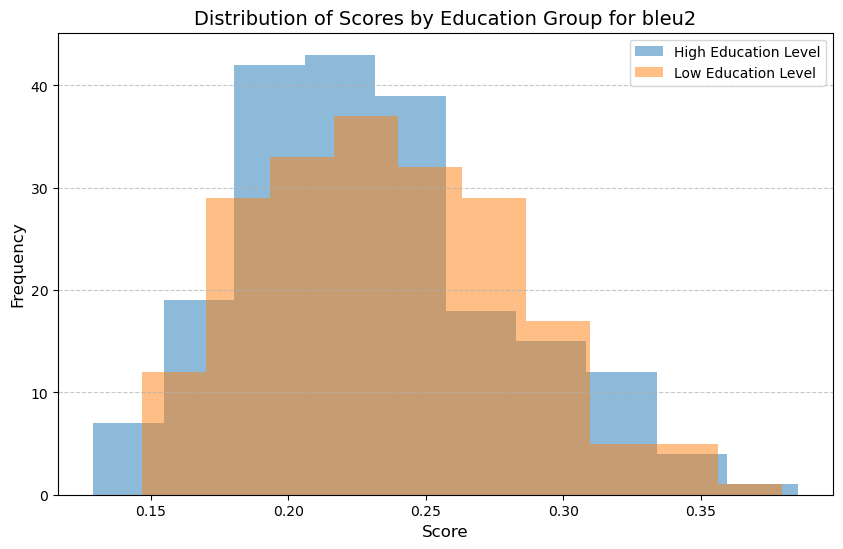

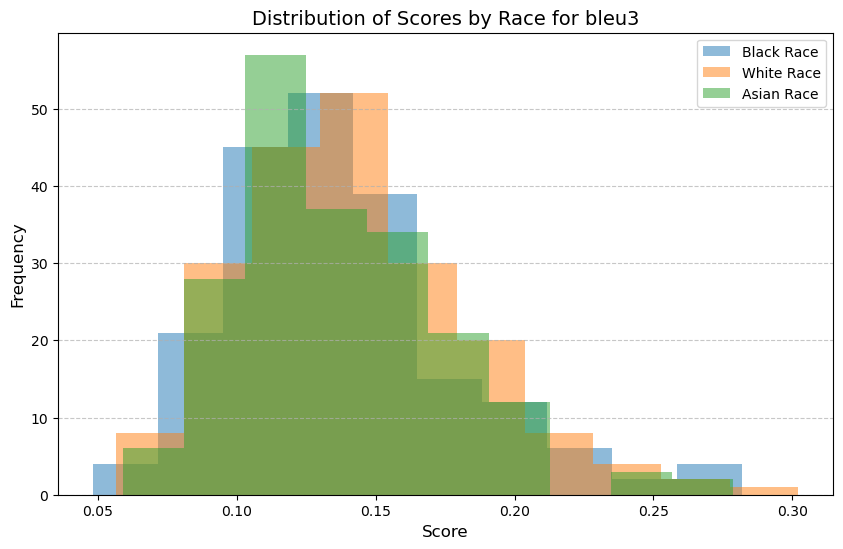

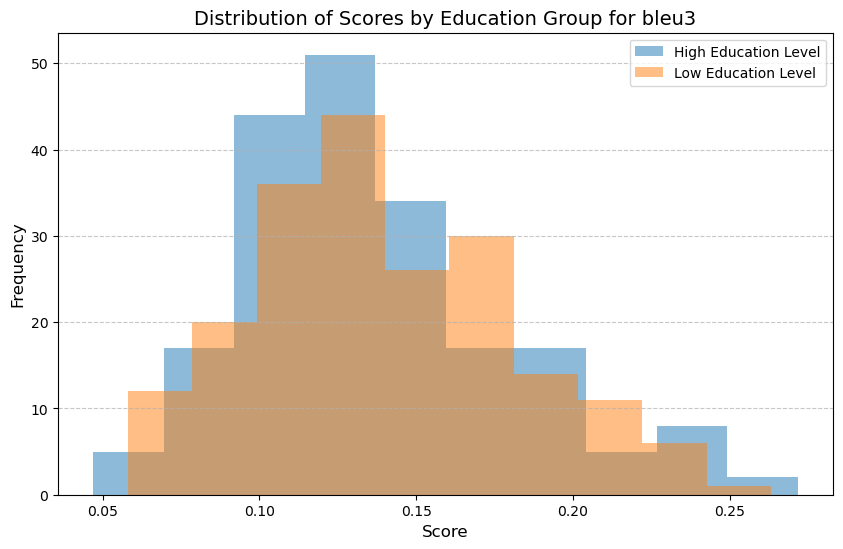

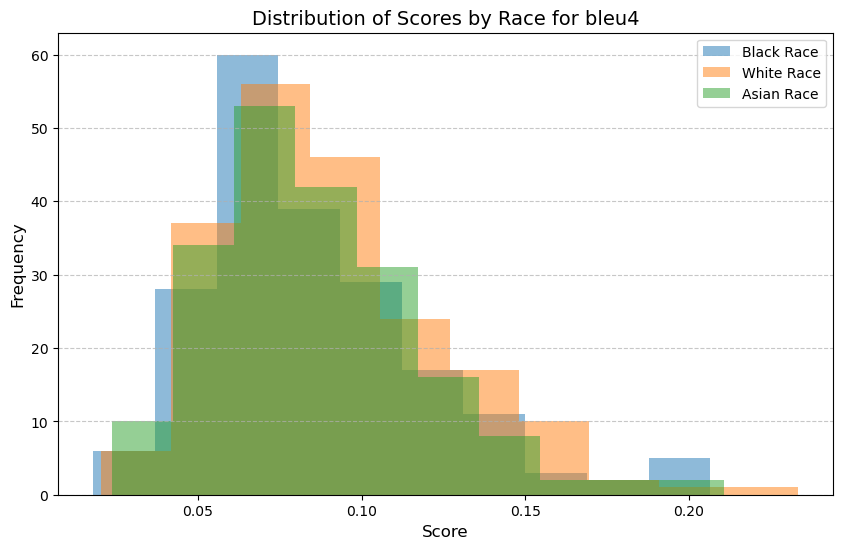

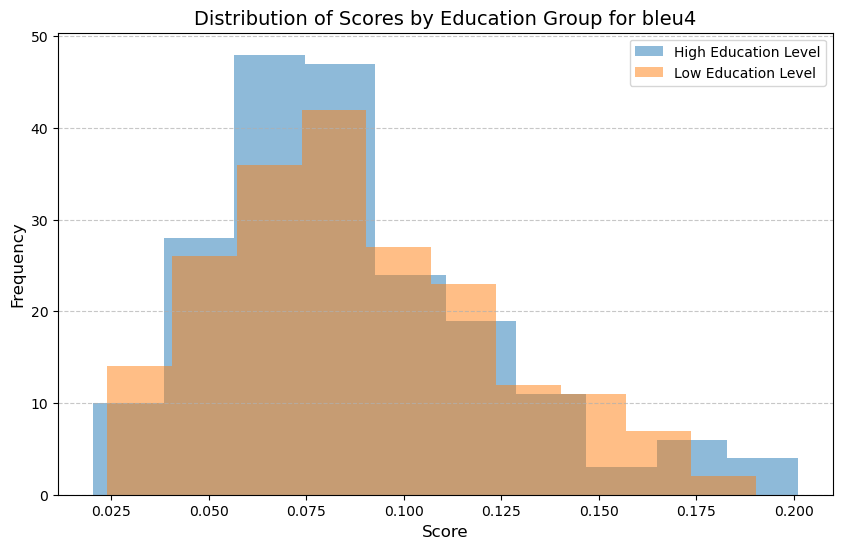

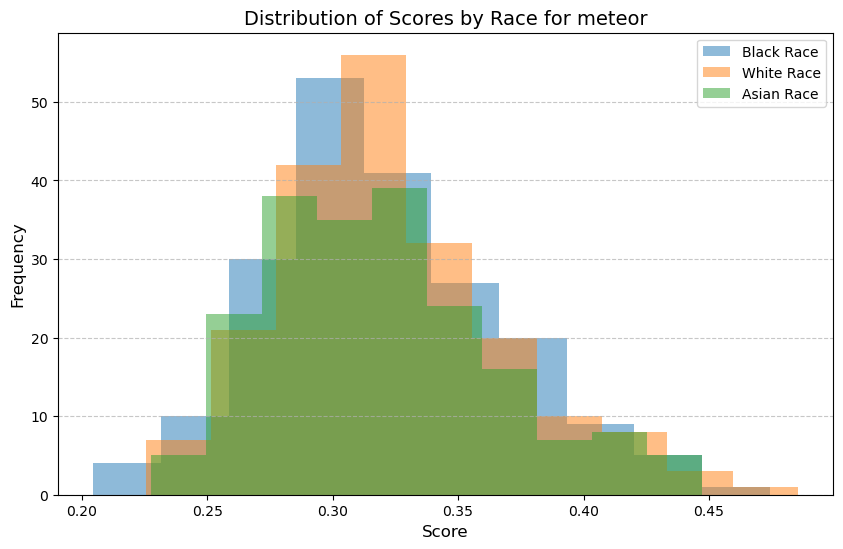

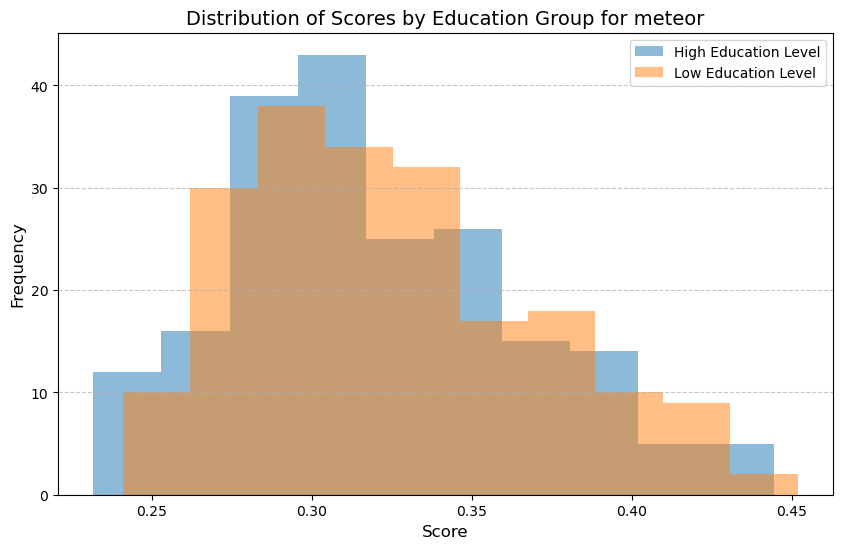

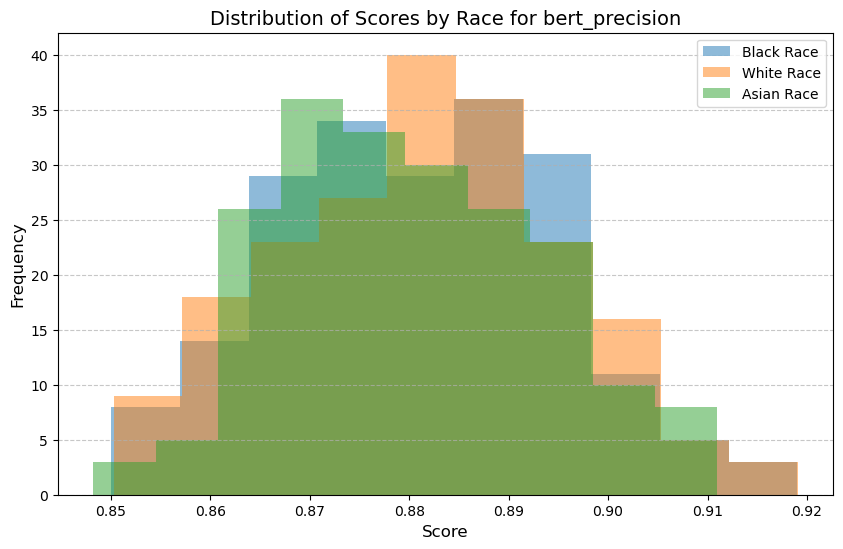

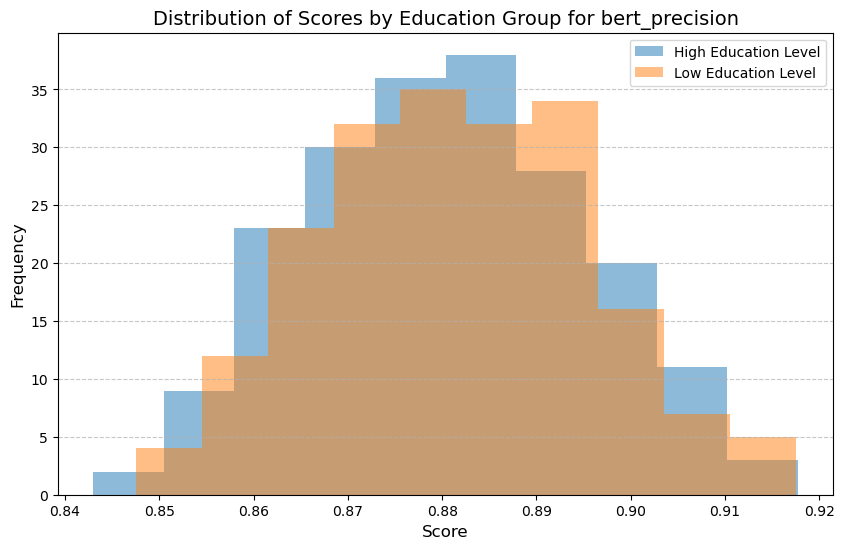

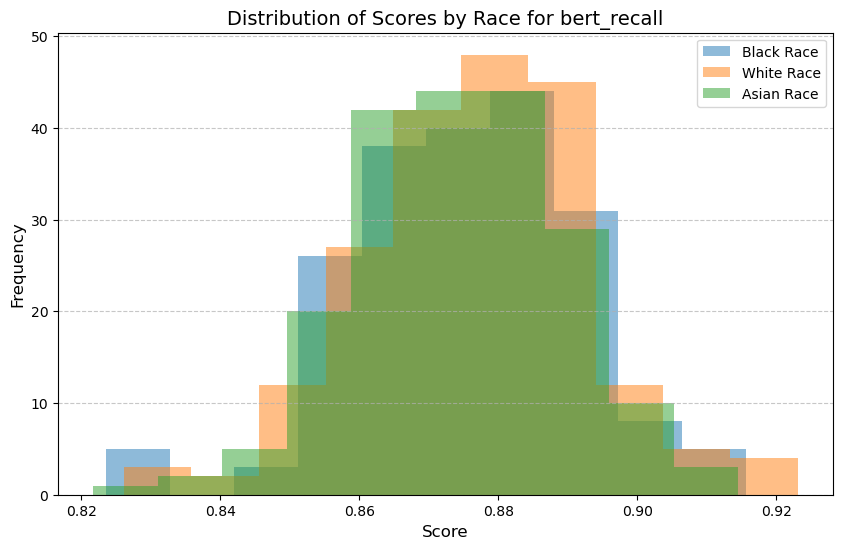

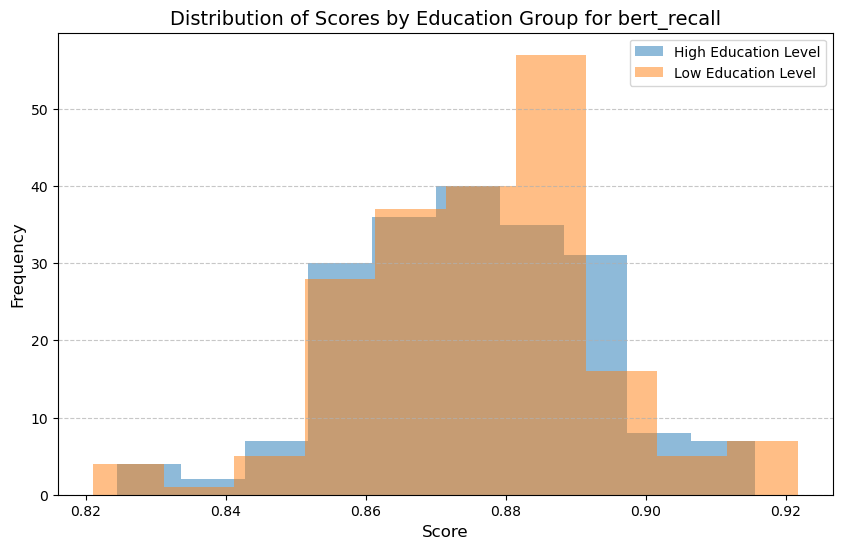

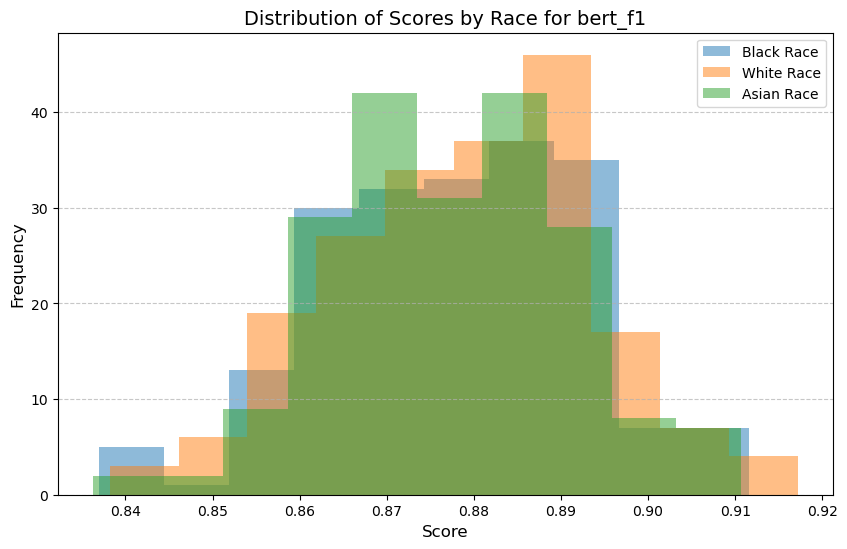

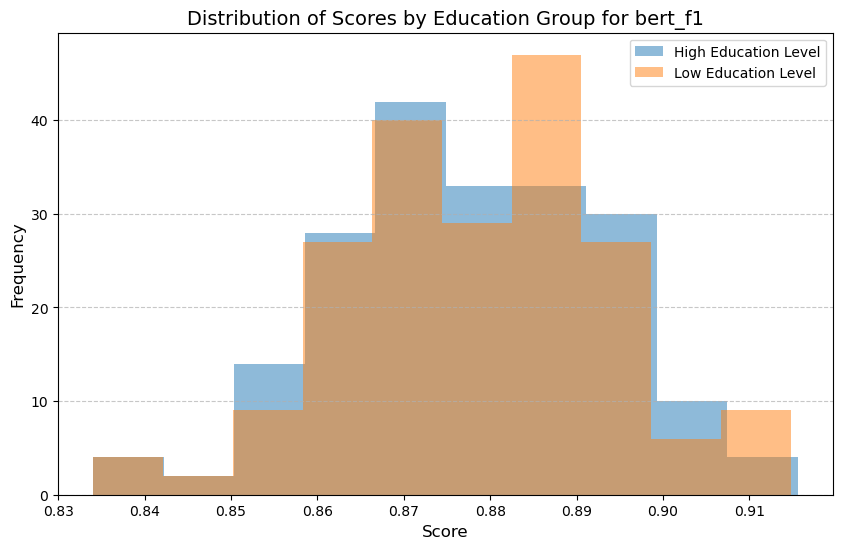

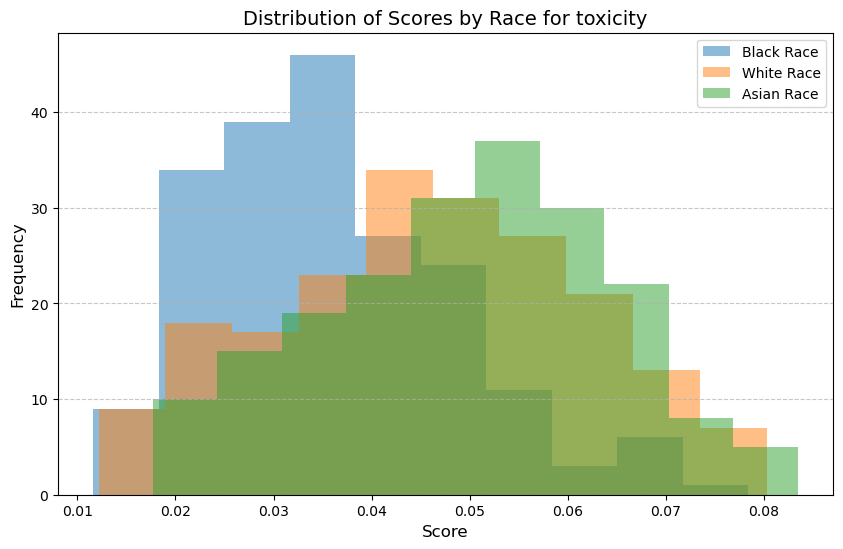

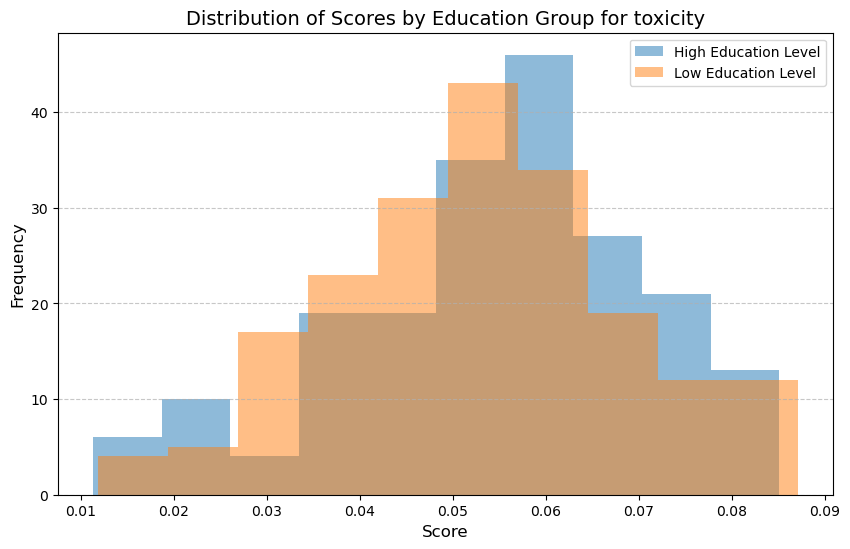

In [11]:
race_groups = ['black', 'white', 'asian']
education_groups = ['high_education', 'low_education']

# Extract unique metrics
metrics = ['rouge1', 'rouge2', 'rouge3', 'rougeL', 'bleu1', 'bleu2', 'bleu3', 'bleu4', 'meteor', 'bert_precision', 'bert_recall', 'bert_f1', 'toxicity']

# Define more informative group labels for the legend
race_labels = {
    'black': 'Black Race',
    'white': 'White Race',
    'asian': 'Asian Race'
}

education_labels = {
    'high_education': 'High Education Level',
    'low_education': 'Low Education Level'
}

# Updated plot function
def plot_distribution(groups, metric, title, labels):
    plt.figure(figsize=(10, 6))
    for group in groups:
        # Extract relevant columns for the group and metric
        cols = [col for col in results_df.columns if f'transcript_{group}_simulated_notes' in col and metric in col]
        if cols:  # Ensure there are columns to process
            # Combine scores from all columns for the group and metric
            scores = results_df[cols].values.flatten()
            # Plot histogram
            plt.hist(scores, bins=10, alpha=0.5, label=labels[group])
    
    # Add legend, title, and labels
    plt.title(title, fontsize=14)
    plt.xlabel('Score', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

# Generate plots
for metric in metrics:
    plot_distribution(race_groups, metric, f'Distribution of Scores by Race for {metric}', race_labels)
    plot_distribution(education_groups, metric, f'Distribution of Scores by Education Group for {metric}', education_labels)

# Better quality for the paper 

In [8]:
#Define race and education groups
race_groups = ['black', 'white', 'asian']
education_groups = ['high_education', 'low_education']

# Define metrics
metrics = ['toxicity']

# Define more informative group labels for the legend
race_labels = {
    'black': 'Black Race',
    'white': 'White Race',
    'asian': 'Asian Race'
}

education_labels = {
    'high_education': 'High Education Level',
    'low_education': 'Low Education Level'
}

# Define save directory
save_dir = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Figures\High dpi paper for technical check\Figure 6"
os.makedirs(save_dir, exist_ok=True)  # Ensure directory exists

# Updated plot function without title
def plot_distribution(groups, metric, labels, save_name):
    plt.figure(figsize=(10, 6))
    for group in groups:
        # Extract relevant columns for the group and metric
        cols = [col for col in results_df.columns if f'transcript_{group}_simulated_notes' in col and metric in col]
        if cols:  # Ensure there are columns to process
            # Combine scores from all columns for the group and metric
            scores = results_df[cols].values.flatten()
            # Plot histogram
            plt.hist(scores, bins=10, alpha=0.5, label=labels[group])
    
    # Add legend, labels, and grid
    plt.xlabel('Toxicity scores', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Save the figure at 300 DPI
    save_path = os.path.join(save_dir, f"{save_name}.png")
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close()

# Generate and save plots
for metric in metrics:
    plot_distribution(race_groups, metric, race_labels, f"{metric}_by_race")
    plot_distribution(education_groups, metric, education_labels, f"{metric}_by_education")

print(f"Figures saved successfully in: {save_dir}")


Figures saved successfully in: C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Figures\High dpi paper for technical check\Figure 6


In [12]:

# Function to perform paired t-tests and store results
def perform_paired_ttest(groups, metric, df):
    results = []
    for i, group1 in enumerate(groups):
        for j, group2 in enumerate(groups):
            if i < j:  # Avoid duplicate pairings
                # Extract relevant columns for each group and metric
                cols1 = [col for col in df.columns if f'transcript_{group1}_simulated_notes' in col and metric in col]
                cols2 = [col for col in df.columns if f'transcript_{group2}_simulated_notes' in col and metric in col]

                if cols1 and cols2:  # Ensure both groups have columns to compare
                    # Combine scores from all columns for the groups and metric
                    scores1 = df[cols1].mean(axis=1)  # Average scores across all columns for group1
                    scores2 = df[cols2].mean(axis=1)  # Average scores across all columns for group2

                    # Perform paired t-test
                    t_stat, p_value = ttest_rel(scores1, scores2, nan_policy='omit')

                    # Append results
                    results.append({
                        'Metric': metric,
                        'Group1': group1,
                        'Group2': group2,
                        'T-Statistic': t_stat,
                        'P-Value': p_value
                    })
    return results

# Initialize an empty list to store all results
all_results = []

# Perform paired t-tests for race groups and income groups for all metrics
for metric in metrics:
    race_results = perform_paired_ttest(race_groups, metric, results_df)
    income_results = perform_paired_ttest(education_groups, metric, results_df)
    all_results.extend(race_results + income_results)


paired_T_results_df = pd.DataFrame(all_results)
paired_T_results_df.head(10)

,Metric,Group1,Group2,T-Statistic,P-Value
0,rouge1,black,white,-1.154667,0.255253
1,rouge1,black,asian,0.921313,0.362551
2,rouge1,white,asian,2.508412,0.016396
3,rouge1,high_education,low_education,-0.165212,0.869631
4,rouge2,black,white,-1.081598,0.286074
5,rouge2,black,asian,0.243623,0.808800
6,rouge2,white,asian,1.490355,0.144175
7,rouge2,high_education,low_education,-0.031538,0.975001
8,rouge3,black,white,-1.675094,0.101917
9,rouge3,black,asian,-0.507262,0.614828


In [13]:
bf_threshold = 0.05/paired_T_results_df.shape[0]
significant_results_df = paired_T_results_df[paired_T_results_df['P-Value'] < bf_threshold ]
print(significant_results_df)

      Metric Group1 Group2  T-Statistic       P-Value
48  toxicity  black  white    -8.494136  2.100884e-10
49  toxicity  black  asian   -13.621866  2.078775e-16
50  toxicity  white  asian    -4.860253  1.944638e-05


# Sensitivity analysis

In [17]:
# Step 1: Explicitly process each "transcript_*_simulated_notes_*" column for black, white, and asian
columns_to_process_black = [
    'transcript_black_simulated_notes_1',
    'transcript_black_simulated_notes_2',
    'transcript_black_simulated_notes_3',
    'transcript_black_simulated_notes_4',
    'transcript_black_simulated_notes_5'
]

columns_to_process_white = [
    'transcript_white_simulated_notes_1',
    'transcript_white_simulated_notes_2',
    'transcript_white_simulated_notes_3',
    'transcript_white_simulated_notes_4',
    'transcript_white_simulated_notes_5'
]

columns_to_process_asian = [
    'transcript_asian_simulated_notes_1',
    'transcript_asian_simulated_notes_2',
    'transcript_asian_simulated_notes_3',
    'transcript_asian_simulated_notes_4',
    'transcript_asian_simulated_notes_5'
]

# Create new DataFrames for cleaned text
results_df_cleaned_black = results_df[columns_to_process_black].applymap(lambda text: text.replace("black", "").strip())
results_df_cleaned_white = results_df[columns_to_process_white].applymap(lambda text: text.replace("white", "").strip())
results_df_cleaned_asian = results_df[columns_to_process_asian].applymap(lambda text: text.replace("asian", "").strip())

# Step 2: Calculate toxicity scores for cleaned text
cleaned_toxicity_scores_black = {}
cleaned_toxicity_scores_white = {}
cleaned_toxicity_scores_asian = {}

for col in columns_to_process_black:
    cleaned_toxicity_scores_black[col] = results_df_cleaned_black[col].apply(calculate_toxicity)

for col in columns_to_process_white:
    cleaned_toxicity_scores_white[col] = results_df_cleaned_white[col].apply(calculate_toxicity)

for col in columns_to_process_asian:
    cleaned_toxicity_scores_asian[col] = results_df_cleaned_asian[col].apply(calculate_toxicity)

# Step 3: Calculate the average toxicity for cleaned text
cleaned_toxicity_averages_black = pd.DataFrame(cleaned_toxicity_scores_black).mean(axis=1)
cleaned_toxicity_averages_white = pd.DataFrame(cleaned_toxicity_scores_white).mean(axis=1)
cleaned_toxicity_averages_asian = pd.DataFrame(cleaned_toxicity_scores_asian).mean(axis=1)

# Step 4: Add cleaned average toxicity to the original DataFrame
results_df["cleaned_average_toxicity_black"] = cleaned_toxicity_averages_black
results_df["cleaned_average_toxicity_white"] = cleaned_toxicity_averages_white
results_df["cleaned_average_toxicity_asian"] = cleaned_toxicity_averages_asian


C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_25580\1615991671.py:27: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  results_df_cleaned_black = results_df[columns_to_process_black].applymap(lambda text: text.replace("black", "").strip())
C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_25580\1615991671.py:28: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  results_df_cleaned_white = results_df[columns_to_process_white].applymap(lambda text: text.replace("white", "").strip())
C:\Users\Yang Qing\AppData\Local\Temp\ipykernel_25580\1615991671.py:29: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  results_df_cleaned_asian = results_df[columns_to_process_asian].applymap(lambda text: text.replace("asian", "").strip())


KeyboardInterrupt: 

In [ ]:
# Plot histograms
plt.figure(figsize=(12, 6))

plt.hist(results_df["cleaned_average_toxicity_black"], bins=10, alpha=0.5, label='Black')
plt.hist(results_df["cleaned_average_toxicity_white"], bins=10, alpha=0.5, label='White')
plt.hist(results_df["cleaned_average_toxicity_asian"], bins=10, alpha=0.5, label='Asian')

plt.title("Histogram of Cleaned Average Toxicity by Group")
plt.xlabel("Cleaned Average Toxicity")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# Paired t-tests
t_test_black_white = ttest_rel(results_df["cleaned_average_toxicity_black"], results_df["cleaned_average_toxicity_white"])
t_test_black_asian = ttest_rel(results_df["cleaned_average_toxicity_black"], results_df["cleaned_average_toxicity_asian"])
t_test_white_asian = ttest_rel(results_df["cleaned_average_toxicity_white"], results_df["cleaned_average_toxicity_asian"])

# Print the t-test results
print("Paired t-test (Black vs White):", t_test_black_white)
print("Paired t-test (Black vs Asian):", t_test_black_asian)
print("Paired t-test (White vs Asian):", t_test_white_asian)

KeyError: 'cleaned_average_toxicity_black'

<Figure size 1200x600 with 0 Axes>

## Cleaned black vs all others

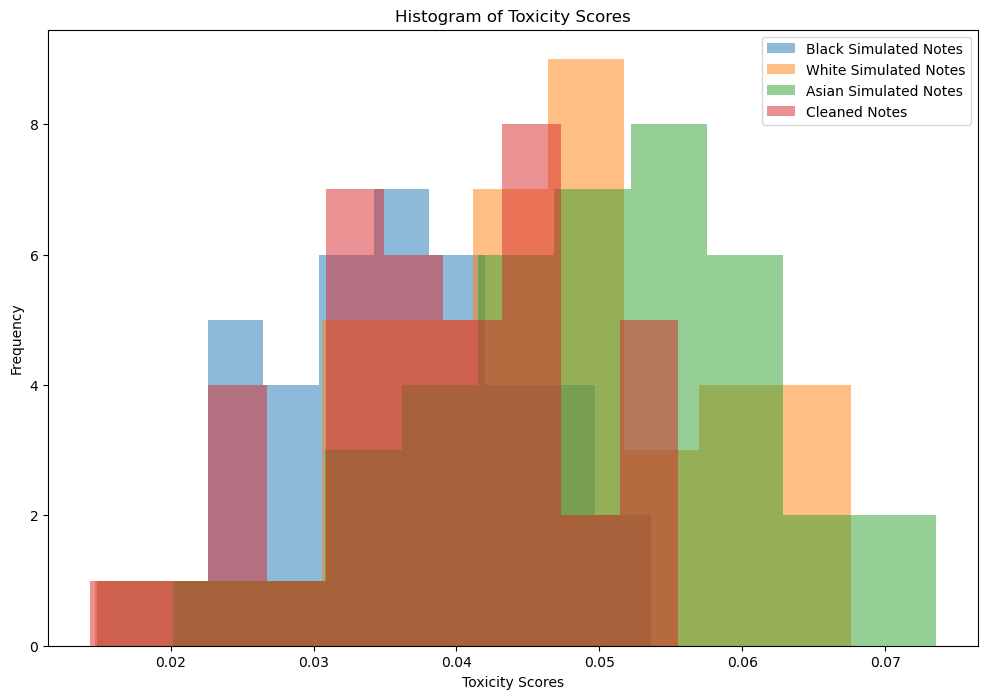

In [ ]:
# Plot histograms for all columns
plt.figure(figsize=(12, 8))

# Histogram for 'black_simulated_notes_average_toxicity'
plt.hist(results_df['black_simulated_notes_average_toxicity'], bins=10, alpha=0.5, label='Black Simulated Notes')

# Histogram for 'white_simulated_notes_average_toxicity'
plt.hist(results_df['white_simulated_notes_average_toxicity'], bins=10, alpha=0.5, label='White Simulated Notes')

# Histogram for 'asian_simulated_notes_average_toxicity'
plt.hist(results_df['asian_simulated_notes_average_toxicity'], bins=10, alpha=0.5, label='Asian Simulated Notes')

# Histogram for 'cleaned_average_toxicity'
plt.hist(results_df['cleaned_average_toxicity'], bins=10, alpha=0.5, label='Cleaned Notes')

# Add labels, title, and legend
plt.xlabel('Toxicity Scores')
plt.ylabel('Frequency')
plt.title('Histogram of Toxicity Scores')
plt.legend()

# Show the plot
plt.show()

In [ ]:
t_stat, p_value = ttest_rel(results_df['black_simulated_notes_average_toxicity'], 
                            results_df['cleaned_average_toxicity'])

# Print the results
print(f"Paired t-test statistic: {t_stat}")
print(f"P-value: {p_value}")

Paired t-test statistic: -6.470015165900267
P-value: 1.1535580433151596e-07


In [ ]:
# Paired t-test for 'cleaned_average_toxicity' and 'white_simulated_notes_average_toxicity'
t_stat_white, p_value_white = ttest_rel(results_df['cleaned_average_toxicity'], 
                                        results_df['white_simulated_notes_average_toxicity'])

# Paired t-test for 'cleaned_average_toxicity' and 'asian_simulated_notes_average_toxicity'
t_stat_asian, p_value_asian = ttest_rel(results_df['cleaned_average_toxicity'], 
                                        results_df['asian_simulated_notes_average_toxicity'])

# Print the results
print(f"Paired t-test statistic (White): {t_stat_white}, P-value: {p_value_white}")
print(f"Paired t-test statistic (Asian): {t_stat_asian}, P-value: {p_value_asian}")

Paired t-test statistic (White): -5.2960940357731285, P-value: 4.901452873555102e-06
Paired t-test statistic (Asian): -9.555493706932463, P-value: 9.126338083273338e-12


In [ ]:
print(bf_threshold)

0.0009615384615384616
